# 커밋과 .gitignore

**이 노트북에서 할 일**

1. 임시 폴더에 연습용 Git 저장소를 만들고 파일 세 개의 상태를 확인합니다.
2. 무시 규칙과 프로그램을 커밋 두 개로 나눠 기록하고, 바뀐 줄을 `git diff`로 읽습니다.
3. 이미 커밋한 로그 파일에 무시 규칙을 늦게 추가해 보고, 추적을 멈추는 방법으로 고칩니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 모델 호출은 0번이고 비용은 들지 않습니다.
실행 시간은 1분 이내입니다. Ch 1 05절에서 설치를 확인한 Git이 필요합니다.

**기준 Git 버전** — Git은 2.28 이상이 필요합니다. 교재 출력은 Git 2.34.1로 만들었고, 새 버전에서는 안내 문구가 조금 다를 수 있습니다.

실습 폴더 `labs/part1/ch03-git-github`에서 Ch 1 3절처럼 `uv sync --locked`로 환경을 만듭니다.
커널에서 이 폴더의 `.venv`를 고른 뒤 첫 셀부터 순서대로 실행합니다.
저장소는 운영체제의 임시 폴더에 만들고, GitHub 계정이나 원격 저장소는 쓰지 않습니다.

## 오늘 볼 그림

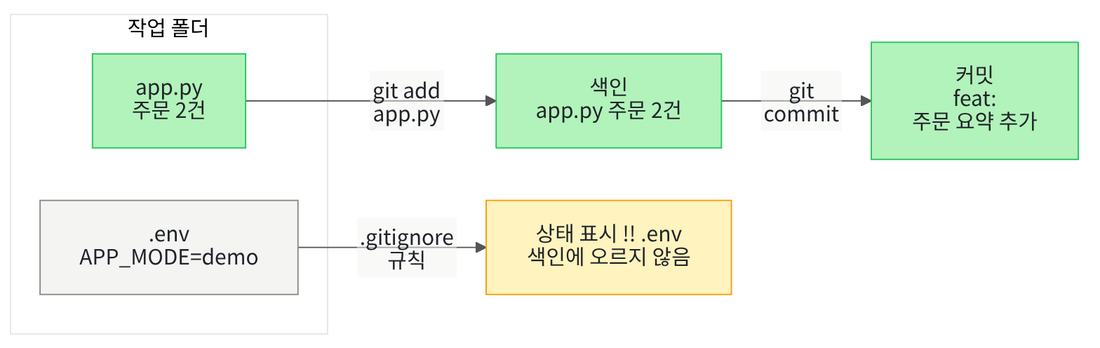

왼쪽에서 오른쪽으로 읽습니다. 초록 상자는 파일 상태가 머무는 자리이고, 화살표 위 글자는 자리를 옮기는 명령입니다.
회색 상자 `.env`는 무시 규칙에 걸려 노란 상자의 `!!` 표시를 받고, 색인으로 가지 않습니다.

## 1. 준비

이 절은 설치할 패키지가 없습니다. 이 노트북은 파일을 만들고 Git 저장소에 기록합니다.
Ch 2 08절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다. 실습 폴더에는 파일이 생기지 않습니다.

코드의 import 두 줄은 Ch 2 07절에서 배운 import 문입니다. 표준 라이브러리 모듈 os와 tempfile을 불러옵니다.

In [1]:
# 저장소로 쓸 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch03-01-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다. 뒤에서 이 빈 폴더를 Git 저장소로 만듭니다.

## 2. git 명령을 실행하는 함수

터미널에 치는 git 명령을 노트북에서도 같은 모양으로 실행하려고 함수 하나를 만듭니다.
예를 들어 셀에 `run_git("status --short")`라고 쓰면 터미널의 `git status --short`를 실행합니다.

함수의 뼈대는 Ch 2 08절의 `run_pytest()`와 같습니다. 명령 목록을 `subprocess.run()` 함수로 실행하고 출력을 보여 줍니다.
달라진 곳은 세 군데입니다.

- 명령 글 앞에 `"git "`을 붙입니다. 글자와 글자 사이의 `+`는 두 글을 이어 붙인 새 글을 만듭니다.
- 모듈 shlex의 `split()` 함수가 명령 글을 낱말 목록으로 나눕니다. 따옴표로 묶은 커밋 메시지는 공백이 있어도 한 낱말로 남습니다.
- 인자 `text=True` 대신 `encoding="utf-8"`을 적습니다. 출력을 글로 받는 것은 같고, 글자를 읽는 규칙을 UTF-8로 정합니다.

인자 `text=True`는 컴퓨터에 정해진 기본 규칙으로 글자를 읽습니다. 그 규칙이 UTF-8이 아니면 한글 커밋 메시지가 깨질 수 있습니다.
Ch 2 05절 `open()`에 적은 것과 같은 `encoding` 인자입니다. 다른 운영체제에서는 이번에 실행하지 않았습니다.

함수는 화면에 쓴 글(`stdout`)과 오류 글(`stderr`)을 이어서 출력합니다. 종료 코드가 0이 아닐 때만 그 숫자도 출력합니다.
반환하는 값이 없으므로 정의 줄에 `->` 표시를 적지 않았습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [2]:
# git 명령 한 줄을 실행하고, 터미널처럼 명령과 출력을 함께 보여 주는 함수
import shlex
import subprocess


def run_git(command: str):
    # "git " 뒤에 명령 글을 이어 붙입니다
    full_command = "git " + command
    # split()은 따옴표로 묶은 메시지를 공백이 있어도 한 낱말로 둡니다
    arguments = shlex.split(full_command)
    # Ch 2 08절처럼 출력을 모아 두고, 글자는 UTF-8 규칙으로 읽습니다
    result = subprocess.run(arguments, capture_output=True, encoding="utf-8")
    print("$", full_command)
    print(result.stdout + result.stderr)
    # 종료 코드 0은 오류 없이 끝났다는 뜻입니다. 0이 아닐 때만 숫자를 보여 줍니다
    if result.returncode != 0:
        print("종료 코드:", result.returncode)

**결과 읽기** — 예상대로 출력이 없습니다. 함수를 만들기만 했습니다.

먼저 Git 버전을 출력해 함수가 동작하는지 확인합니다. 명령 `git --version`은 Ch 1 05절에서 버전을 물은 명령입니다.

In [3]:
# 설치된 Git 버전을 출력해 함수가 동작하는지 확인합니다
run_git("--version")

$ git --version
git version 2.34.1



**결과 읽기** — 첫 줄 `$ git --version`은 실행한 명령이고, 둘째 줄 `git version 2.34.1`이 결과입니다.
버전 숫자는 컴퓨터마다 다를 수 있습니다. 다음 셀의 `git init -b main` 명령은 Git 2.28 이상에서 동작합니다.

## 3. 임시 폴더를 저장소로 만들기

Ch 1 05절에서는 명령 `git init`으로 임시 폴더를 저장소로 만들었습니다. 이번에는 옵션 `-b main`을 붙입니다.
이 옵션은 첫 브랜치 이름을 main으로 정합니다. 브랜치(branch)는 커밋이 이어지는 줄기의 이름이고, 02절에서 배웁니다.
준비 셀에서 작업 위치를 옮겼으므로 명령은 그 임시 폴더에서 실행됩니다.

실행 전에 예상합니다. 빈 저장소를 만들었다는 줄이 나오고, 파일 목록에 `.git` 폴더가 생길 것입니다.

In [4]:
# 현재 작업 폴더를 Git 저장소로 만들고, 첫 브랜치 이름을 main으로 정합니다
run_git("init -b main")
# 저장소를 만들면 변경 기록을 담을 .git 폴더가 생깁니다
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

$ git init -b main
Initialized empty Git repository in [사용자 폴더]/tmp/ch03-01-qn70t8ku/.git/

현재 작업 폴더의 파일: ['.git']


**결과 읽기** — 둘째 줄 `Initialized empty Git repository`는 빈 저장소를 만들었다는 뜻입니다.
줄 끝의 임시 폴더 경로는 실행할 때마다 달라집니다. 출력의 `[사용자 폴더]`는 교재를 실행한 컴퓨터의 사용자 폴더를 가린 표시입니다.
파일 목록은 `['.git']`입니다. 이 `.git` 폴더에 변경 기록이 모이고, Ch 1 05절처럼 직접 고치거나 지우지 않습니다.

커밋에는 작성자 이름과 전자우편 주소가 함께 기록됩니다. Ch 1 05절에서는 커밋할 때마다 옵션 `-c`로 이 두 값을 넣었습니다.
옵션 `-c`는 그 명령 한 번에만 쓰였습니다.

이번에는 명령 `git config`로 이 연습 저장소에 작성자 정보를 적어 둡니다.
그러면 뒤의 커밋마다 다시 적지 않아도 됩니다. 옵션 `--global`을 붙이지 않았으므로 내 컴퓨터의 다른 저장소 설정은 바뀌지 않습니다.

In [5]:
# 이 저장소에만 작성자 이름과 전자우편 주소를 적습니다
run_git('config user.name "Ch3 Student"')
run_git("config user.email student@example.com")
# 값 없이 설정 이름만 주면 저장된 값을 보여 줍니다
run_git("config user.name")

$ git config user.name "Ch3 Student"

$ git config user.email student@example.com

$ git config user.name
Ch3 Student



**결과 읽기** — 설정하는 두 명령은 출력이 없습니다. 마지막 명령의 결과 `Ch3 Student`가 저장된 작성자 이름입니다.

## 4. 파일 세 개를 만들고 상태 보기

작업 폴더에 파일 세 개를 만듭니다. 프로그램 파일 `app.py`는 주문 건수를 출력합니다.
무시 규칙 파일 `.gitignore`에는 `.env`와 `__pycache__/` 두 줄을 적습니다. 환경 설정 파일 `.env`에는 연습용 값 `APP_MODE=demo`만 넣습니다.

파일은 Ch 2 05절의 쓰기 모드 `"w"`와 `with open()` 블록으로 저장합니다. 두 줄짜리 무시 규칙은 Ch 1 04절에서 본 여러 줄 글 `"""…"""`로 적습니다.
한 줄짜리 글 끝의 `\n`은 Ch 1 03절에서 본 줄바꿈 한 글자입니다.

명령 `git status --short`는 Ch 1 05절에서 쓴 짧은 상태 목록입니다. 옵션 `--ignored`를 붙이면 무시 규칙에 걸린 파일도 목록에 나옵니다.
실행 전에 예상합니다. 새 파일에는 Ch 1 05절처럼 `??` 표시가 붙고, 무시 규칙에 적은 `.env`만 다른 표시를 받을 것입니다.

In [6]:
# 작업 폴더에 프로그램, 무시 규칙, 환경 설정 파일을 만듭니다
ignore_text = """.env
__pycache__/
"""
with open("app.py", "w", encoding="utf-8") as file:
    file.write('print("주문 2건")\n')
with open(".gitignore", "w", encoding="utf-8") as file:
    file.write(ignore_text)
with open(".env", "w", encoding="utf-8") as file:
    file.write("APP_MODE=demo\n")
# 세 파일이 Git에게 어떤 상태로 보이는지 확인합니다
run_git("status --short --ignored")

$ git status --short --ignored
?? .gitignore
?? app.py
!! .env



**결과 읽기** — 줄 앞의 두 글자가 파일 상태입니다. 물음표 두 개 `?? app.py`는 아직 추적하지 않는 새 파일이라는 뜻입니다.
느낌표 두 개 `!! .env`는 무시 규칙에 걸린 파일입니다. 같은 폴더에 있어도 환경 설정 파일만 다른 표시를 받았습니다.

추적한다는 말은 Git이 그 파일의 변경을 기록 대상으로 삼는다는 뜻입니다. Ch 1 05절에서 「처음 보는 파일」로 읽은 표시가 `??`입니다.

## 5. 무시 규칙을 첫 커밋으로 기록하기

커밋에 넣을 파일은 `git add` 명령으로 먼저 고릅니다. 고른 파일 상태는 색인(index)에 올라갑니다.

색인은 다음 커밋에 넣을 파일 상태를 모아 두는 자리입니다. Ch 1 05절에서 「기록할 목록」이라고 부른 자리입니다.
스테이징 영역(staging area)이라고도 부릅니다. 이번에는 무시 규칙 파일 하나만 고릅니다.

In [7]:
# 무시 규칙 파일 하나만 색인에 올리고 상태를 다시 봅니다
run_git("add .gitignore")
run_git("status --short")

$ git add .gitignore

$ git status --short
A  .gitignore
?? app.py



**결과 읽기** — 상태 줄 `A  .gitignore`의 A는 색인에 새로 올린 파일이라는 뜻입니다.
프로그램 파일은 여전히 `?? app.py`로 남았습니다. 이번 목록에는 옵션 `--ignored`를 빼서 `.env` 줄이 보이지 않습니다.

색인에 고른 상태를 커밋으로 기록합니다. Ch 1 05절에서는 커밋을 지금 파일의 모습을 한 번 기록하는 일이라고 했습니다.
이제 색인을 알았으니 뜻을 더 정확히 적습니다. 커밋(commit)은 색인에 고른 파일 상태와 설명 메시지를 묶어 이력에 남긴 기록입니다.

옵션 `-m` 뒤의 따옴표 안 글이 커밋 메시지입니다. 앞머리 `chore:`는 변경 목적을 표시하는 이 교재의 팀 관례입니다.
필수 문법은 아니며, 저장소마다 규칙이 다를 수 있습니다.

In [8]:
# 색인에 올린 무시 규칙 파일을 첫 커밋으로 기록합니다
run_git('commit -m "chore: 생성 파일 추적 제외"')

$ git commit -m "chore: 생성 파일 추적 제외"
[main (root-commit) 8f5623d] chore: 생성 파일 추적 제외
 1 file changed, 2 insertions(+)
 create mode 100644 .gitignore



**결과 읽기** — 요약 줄 `1 file changed`는 이 커밋에 파일 하나가 들어갔다는 뜻입니다. 마지막 줄에 `.gitignore`가 보입니다.
대괄호 안 끝의 일곱 글자는 커밋 번호(해시)의 앞부분이며 실행할 때마다 달라집니다. 표시 `root-commit`은 저장소의 첫 커밋이라는 뜻입니다.

## 6. 프로그램을 두 번째 커밋으로 기록하기

이번에는 프로그램 파일만 고르고, 새 기능을 알리는 `feat:` 메시지로 커밋합니다.
목적이 다른 변경을 커밋 두 개로 나누면 메시지만 읽어도 무엇을 바꿨는지 알 수 있습니다.
명령 `git log --oneline`은 커밋을 최신 순서로 한 줄씩 보여 줍니다.

In [9]:
# 프로그램 파일을 두 번째 커밋으로 기록하고 이력과 상태를 봅니다
run_git("add app.py")
run_git('commit -m "feat: 주문 요약 추가"')
run_git("log --oneline")
run_git("status --short --ignored")

$ git add app.py

$ git commit -m "feat: 주문 요약 추가"
[main 4a81f12] feat: 주문 요약 추가
 1 file changed, 1 insertion(+)
 create mode 100644 app.py

$ git log --oneline
4a81f12 feat: 주문 요약 추가
8f5623d chore: 생성 파일 추적 제외

$ git status --short --ignored
!! .env



**결과 읽기** — 이력의 첫 줄은 방금 만든 `feat: 주문 요약 추가`이고, 둘째 줄은 `chore: 생성 파일 추적 제외`입니다.
마지막 상태 목록에는 `!! .env` 한 줄만 남았습니다. 추적하는 두 파일은 커밋과 내용이 같아서 목록에 나오지 않습니다.
커밋 번호는 실행마다 달라지므로 메시지로 커밋을 구분합니다.

## 7. 값 하나 바꿔 보기 — 주문 2건을 3건으로

프로그램의 숫자 하나만 2에서 3으로 바꿉니다. Ch 1 05절에서 `hello.py`의 수량을 2에서 3으로 바꾼 것과 같은 실험입니다.
아직 `git add`를 하지 않았으므로 바뀐 내용은 작업 폴더에만 있습니다.

실행 전에 예상합니다. 명령 `git diff`는 작업 폴더와 색인을 비교합니다.
색인에는 아직 2건이 있으므로 빼기(-) 줄에 2건, 더하기(+) 줄에 3건이 나올 것입니다.

In [10]:
# 주문 건수를 3건으로 고치고, 작업 폴더의 변경을 확인합니다
with open("app.py", "w", encoding="utf-8") as file:
    file.write('print("주문 3건")\n')
run_git("status --short")
# 작업 폴더와 색인을 비교합니다
run_git("diff")

$ git status --short
 M app.py

$ git diff
diff --git a/app.py b/app.py
index 0bde456..4333761 100644
--- a/app.py
+++ b/app.py
@@ -1 +1 @@
-print("주문 2건")
+print("주문 3건")



**결과 읽기** — 상태 줄 `M app.py`의 M은 수정된 파일이라는 뜻입니다.
상태 표시는 두 칸입니다. Ch 1 05절 노트북은 앞 빈칸을 떼어 내 글자 하나만 읽었고, 이번에는 두 칸을 모두 읽습니다.
첫 칸은 색인의 변화, 둘째 칸은 작업 폴더의 변화입니다. 이번 M은 둘째 칸에 있습니다.

비교 결과의 `-print("주문 2건")` 줄은 색인의 내용이고, `+print("주문 3건")` 줄은 작업 폴더의 내용입니다.

이번에는 변경을 색인에 올린 뒤 같은 비교를 다시 합니다. Ch 1 05절 주의 메모에서 기기 셸로만 확인한 장면입니다.
실행 전에 예상합니다. 작업 폴더와 색인이 같아지므로 `git diff`에는 아무것도 나오지 않을 것입니다.

옵션을 붙인 `git diff --cached`는 색인과 마지막 커밋을 비교합니다.
지금 기준이 되는 마지막 커밋을 가리키는 이름이 HEAD입니다.

In [11]:
# 변경을 색인에 올리고, 두 가지 비교를 다시 봅니다
run_git("add app.py")
run_git("status --short")
run_git("diff")
# 색인과 마지막 커밋(HEAD)을 비교합니다
run_git("diff --cached")

$ git add app.py

$ git status --short
M  app.py

$ git diff

$ git diff --cached
diff --git a/app.py b/app.py
index 0bde456..4333761 100644
--- a/app.py
+++ b/app.py
@@ -1 +1 @@
-print("주문 2건")
+print("주문 3건")



**결과 읽기** — 상태 줄이 `M  app.py`로 바뀌어 M이 첫 칸으로 옮겨졌습니다.
명령 `git diff` 아래에는 아무 줄도 없습니다. 작업 폴더와 색인이 같아졌기 때문입니다.
옵션을 붙인 비교에는 앞 셀과 같은 `+print("주문 3건")` 줄이 나왔습니다. 이제 차이는 색인과 마지막 커밋 사이에 있습니다.

색인에 올린 수정을 세 번째 커밋으로 기록합니다. 메시지 앞머리 `fix:`는 잘못된 값을 고쳤다는 표시입니다.
메시지에는 파일 이름보다 바꾼 이유를 적습니다.

In [12]:
# 건수 수정을 세 번째 커밋으로 기록하고 이력을 봅니다
run_git('commit -m "fix: 주문 건수 수정"')
run_git("log --oneline")

$ git commit -m "fix: 주문 건수 수정"
[main b9e27b4] fix: 주문 건수 수정
 1 file changed, 1 insertion(+), 1 deletion(-)

$ git log --oneline
b9e27b4 fix: 주문 건수 수정
4a81f12 feat: 주문 요약 추가
8f5623d chore: 생성 파일 추적 제외



**결과 읽기** — 요약 줄 `1 insertion(+), 1 deletion(-)`은 한 줄을 더하고 한 줄을 지웠다는 뜻입니다.
이력에는 커밋 세 개가 최신 순서로 있고, 맨 위가 `fix: 주문 건수 수정`입니다.

## 8. Before — 이미 커밋한 로그 파일에 무시 규칙 추가하기

실행 기록 파일 `debug.log`를 실수로 먼저 커밋했다고 해 봅니다. 그 뒤에 무시 규칙 `*.log`를 추가합니다.
별표 `*`는 아무 글자와 일치하므로 `.log`로 끝나는 모든 파일을 가리킵니다. 먼저 로그 파일을 만들고 커밋합니다.

In [13]:
# Before: 로그 파일을 먼저 커밋합니다
with open("debug.log", "w", encoding="utf-8") as file:
    file.write("first run\n")
run_git("add debug.log")
run_git('commit -m "chore: 디버그 로그 기록"')

$ git add debug.log

$ git commit -m "chore: 디버그 로그 기록"
[main 8effaf6] chore: 디버그 로그 기록
 1 file changed, 1 insertion(+)
 create mode 100644 debug.log



**결과 읽기** — 마지막 줄의 `debug.log`로 로그 파일이 커밋에 들어간 것을 확인합니다. 이제 이 파일은 추적하는 파일입니다.

무시 규칙 파일 끝에 `*.log` 한 줄을 덧붙이고 로그 내용도 바꿉니다. Ch 2 05절의 쓰기 모드 `"w"`는 내용을 지우고 새로 씁니다.
이어 쓰기 모드 `"a"`는 기존 내용을 두고 그 뒤에 이어 씁니다. Ch 2 05절에서 실행하지 않은 모드입니다.

실행 전에 예상합니다. 규칙이 로그 파일에도 적용된다면 상태 목록에서 로그 파일 줄이 사라져야 합니다.

In [14]:
# Before: 무시 규칙을 추가한 뒤 로그 내용을 바꾸고 상태를 봅니다
with open(".gitignore", "a", encoding="utf-8") as file:
    file.write("*.log\n")
with open("debug.log", "w", encoding="utf-8") as file:
    file.write("second run\n")
run_git("status --short")

$ git status --short
 M .gitignore
 M debug.log



**결과 읽기** — 예상과 달리 `M debug.log` 줄이 목록에 남았습니다. 규칙을 추가했는데도 로그 파일의 변경이 계속 기록 대상입니다.
위 줄의 `M .gitignore`는 규칙 파일을 고쳤다는 표시입니다.

명령 `git check-ignore -v`는 파일에 걸린 무시 규칙과 그 규칙의 줄 번호를 보여 줍니다. 로그 파일에 규칙이 걸리는지 확인합니다.

In [15]:
# Before: 로그 파일에 무시 규칙이 적용되는지 확인합니다
run_git("check-ignore -v debug.log")

$ git check-ignore -v debug.log

종료 코드: 1


**결과 읽기** — 규칙 줄은 나오지 않고 `종료 코드: 1`만 나왔습니다. 이 명령에서 종료 코드 1은 적용된 무시 규칙이 없다는 뜻입니다.
무시 규칙은 아직 추적하지 않는 파일에만 적용됩니다. 로그 파일은 이미 추적하고 있었기 때문에 규칙이 걸리지 않았습니다.

## 9. After — 색인에서만 빼서 추적 멈추기

명령 `git rm --cached debug.log`는 파일을 색인에서만 뺍니다. 옵션 `--cached`가 있으면 작업 폴더의 실제 파일은 지우지 않습니다.
실제 파일이 남았는지는 `os.listdir()` 목록에 이름이 있는지 연산자 `in`으로 확인합니다. 연산자 `in`은 Ch 2 03절에서 배웠습니다.

실행 전에 예상합니다. 상태 목록에 삭제 표시 D가 나오고, 로그 파일은 폴더에 그대로 있어야 합니다.

In [16]:
# After: 로그 파일을 색인에서만 빼고 상태를 봅니다
run_git("rm --cached debug.log")
run_git("status --short")
# 작업 폴더에 실제 파일이 남았는지 확인합니다
file_names = os.listdir()
print("debug.log가 폴더에 있는가:", "debug.log" in file_names)

$ git rm --cached debug.log
rm 'debug.log'

$ git status --short
 M .gitignore
D  debug.log

debug.log가 폴더에 있는가: True


**결과 읽기** — 상태 줄 `D  debug.log`는 다음 커밋에서 이 파일을 추적 목록에서 뺀다는 뜻입니다.
마지막 줄 `debug.log가 폴더에 있는가: True`로 실제 파일이 남아 있음을 확인합니다.

규칙 파일도 색인에 올리고 두 변경을 한 커밋으로 기록합니다. 두 변경은 「로그 파일 추적을 멈춘다」는 한 가지 목적입니다.

In [17]:
# After: 추적 해제와 무시 규칙을 한 커밋으로 기록합니다
run_git("add .gitignore")
run_git('commit -m "chore: 로그 파일 추적 제외"')

$ git add .gitignore

$ git commit -m "chore: 로그 파일 추적 제외"
[main 24c6146] chore: 로그 파일 추적 제외
 2 files changed, 1 insertion(+), 1 deletion(-)
 delete mode 100644 debug.log



**결과 읽기** — 요약 줄 `2 files changed`는 규칙 파일과 로그 파일이 함께 이 커밋에 들어갔다는 뜻입니다.
마지막 줄 `delete mode 100644 debug.log`는 저장소의 추적 목록에서 로그 파일을 뺐다는 표시입니다.

로그 내용을 한 번 더 바꾸고 세 가지를 확인합니다. 명령 `git ls-files`는 추적 중인 파일 목록을 보여 줍니다.
추적이 멈췄다면 추적 목록과 상태 목록은 비어 있고, 규칙 확인에는 규칙 줄이 나와야 합니다.

In [18]:
# After: 로그 내용을 다시 바꾼 뒤 추적 목록, 무시 규칙, 상태를 확인합니다
with open("debug.log", "w", encoding="utf-8") as file:
    file.write("third run\n")
run_git("ls-files debug.log")
run_git("check-ignore -v debug.log")
run_git("status --short")

$ git ls-files debug.log

$ git check-ignore -v debug.log
.gitignore:3:*.log	debug.log

$ git status --short



**결과 읽기** — 추적 목록 명령 아래가 비어 있습니다. 규칙 확인 결과는 `.gitignore:3:*.log`입니다.
무시 규칙 파일의 3번째 줄 규칙이 로그 파일에 걸렸다는 뜻입니다. 마지막 상태 목록도 비어 있습니다.

추적을 멈춰도 지난 커밋에 저장된 내용은 남는지 확인합니다. 이름 `HEAD~1`은 마지막 커밋의 바로 앞 커밋입니다.
명령 `git show` 뒤에 커밋 이름과 콜론, 파일 경로를 적으면 그 커밋에 저장된 파일 내용을 보여 줍니다.

In [19]:
# After: 로그 파일을 커밋했던 지난 커밋에서 파일 내용을 꺼내 봅니다
run_git("show HEAD~1:debug.log")

$ git show HEAD~1:debug.log
first run



**결과 읽기** — 지난 커밋 안의 로그 파일 내용 `first run`이 그대로 나왔습니다.
색인에서 빼고 무시 규칙을 적어도 이미 만든 커밋은 바뀌지 않습니다. 기록에서 내용을 지우는 방법은 05절에서 다룹니다.

## 정리

- 명령 `git add`로 다음 커밋에 넣을 파일을 색인에 고르고, `git commit`으로 고른 상태를 기록합니다.
- 비교 명령 `git diff`는 작업 폴더와 색인을, `git diff --cached`는 색인과 마지막 커밋을 비교합니다.
- 무시 규칙은 추적하지 않는 파일에만 적용됩니다. 이미 추적하는 파일은 `git rm --cached`로 추적을 멈춥니다.

이번에는 Linux의 Git 2.34.1로 실행했습니다. 다른 운영체제에서는 실행하지 않았습니다.
다음 절에서는 기능 브랜치에 커밋을 쌓고 PR로 변경을 검토합니다.